In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import time
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)
print('✓ Libraries imported successfully')

✓ Libraries imported successfully


## Dataset Selection and Loading

In [ ]:
data = pd.read_csv("../data/concrete_data.csv")
data.head(10)

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
5,266.0,114.0,0.0,228.0,0.0,932.0,670.0,90,47.03
6,380.0,95.0,0.0,228.0,0.0,932.0,594.0,365,43.70
7,380.0,95.0,0.0,228.0,0.0,932.0,594.0,28,36.45
8,266.0,114.0,0.0,228.0,0.0,932.0,670.0,28,45.85
9,475.0,0.0,0.0,228.0,0.0,932.0,594.0,28,39.29


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   cement                         1030 non-null   float64
 1   blast_furnace_slag             1030 non-null   float64
 2   fly_ash                        1030 non-null   float64
 3   water                          1030 non-null   float64
 4   superplasticizer               1030 non-null   float64
 5   coarse_aggregate               1030 non-null   float64
 6   fine_aggregate                 1030 non-null   float64
 7   age                            1030 non-null   int64  
 8   concrete_compressive_strength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.5 KB


In [4]:
data.describe()

,cement,blast_furnace_slag,fly_ash,water,superplasticizer,coarse_aggregate,fine_aggregate,age,concrete_compressive_strength
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


In [5]:
# Dataset information
dataset_name = "Concrete Compressive Strength"
dataset_source = "UCI ML Repository"
n_samples = data.shape[0]      # Total number of rows
n_features = data.shape[1]-1     # Number of features (excluding target)
problem_type = "regression"

# Problem statement
problem_statement = """
Predicting the compressive strength of cement (in MPa). Concrete is the most important material in Civil Engineering and
decides the strength, safety and durability of structures made like buildings, bridges, and other infrastructure.
Accurate predictions of strength rather than physical testing (takes approx a month) would help real estate and construction
firms to accelerate project timelines. This makes a data-driven approach rather than a physical approach a critical need
in today's fast-paced world.
"""

# Primary evaluation metric
primary_metric = "rmse"

# Metric justification
metric_justification = """
Root Mean Squared Error (RMSE) is chosen as the primary metric for this problem. RMSE penalizes large errors heavily,
and this matters in predictions of the compressive strength of cement since underestimating strength in a structural
design is catastrophic. An underestimation of strength puts lives at risk -- the people living in a building, commuters
crossing bridges on a regular basis, etc.
"""

print(f"Dataset: {dataset_name}")
print(f"Source: {dataset_source}")
print(f"Samples: {n_samples}, Features: {n_features}")
print(f"Problem Type: {problem_type}")
print(f"Primary Metric: {primary_metric}")

Dataset: Concrete Compressive Strength
Source: UCI ML Repository
Samples: 1030, Features: 8
Problem Type: regression
Primary Metric: rmse


## Data Preprocessing

In [6]:
# No missing values in dataset
# No categorical variables in dataset -- all numerical

# Separating the features and target values
target = "concrete_compressive_strength"
X = data.drop(target, axis=1)
y = data[target]

print("Features:")
print("\n".join(X.columns))
print("\nTarget:")
print(y.name)

Features:
cement
blast_furnace_slag
fly_ash
water
superplasticizer
coarse_aggregate
fine_aggregate 
age

Target:
concrete_compressive_strength


In [7]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Size of training set: {X_train.shape}")
print(f"Size of testing set: {X_test.shape}")

Size of training set: (824, 8)
Size of testing set: (206, 8)


In [8]:
# Feature scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [9]:
train_samples = X_train.shape[0]       # Number of training samples
test_samples = X_test.shape[0]        # Number of test samples
train_test_ratio = 0.8

print(f"Train samples: {train_samples}")
print(f"Test samples: {test_samples}")
print(f"Split ratio: {train_test_ratio:.1%}")

Train samples: 824
Test samples: 206
Split ratio: 80.0%


## Baseline Model Implementation

In [10]:
class BaselineModel:
    """
    Baseline linear model with gradient descent
    """
    def __init__(self, learning_rate=0.01, n_iterations=1000, random_seed=42):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None
        self.loss_history = []
        self.random_seed = random_seed

    def _initialize_weights_and_bias(self, n_features):
        # Assigning random small weights to begin with -- each weight learns different things from gradient descent
        # This helps in breaking symmetry
        np.random.seed(self.random_seed)
        self.weights = (np.random.randn(n_features, 1) * 0.01).ravel()
        self.bias = 0.0

    def _compute_loss(self, y_true, y_pred):
        N = len(y_true)
        return (1/(2*N))*np.sum((y_pred-y_true)**2)

    def _compute_gradients(self, X, y_true, y_pred):
        N = len(y_true)
        errors = y_pred - y_true
        gradient_weights = ((1/N)*np.dot(X.T, errors)).ravel()
        gradient_bias = (1/N)*np.sum(errors)

        return gradient_weights, gradient_bias

    def fit(self, X, y):
        n_samples, n_features = X.shape

        # Initialize parameters
        self._initialize_weights_and_bias(n_features)

        # Gradient descent loop
        for i in range(self.n_iterations):
            # Forward pass
            y_pred = self.predict(X)

            # Compute loss
            loss = self._compute_loss(y, y_pred)

            # Compute gradients
            gradient_weights, gradient_bias = self._compute_gradients(X, y, y_pred)

            # Update weights and bias
            self.weights -= self.lr * gradient_weights
            self.bias -= self.lr * gradient_bias

            # Store loss
            self.loss_history.append(loss)

        return self

    def predict(self, X):
        return (np.dot(X, self.weights) + self.bias).ravel()

print("✓ Baseline model class defined")

✓ Baseline model class defined


In [11]:
# Train baseline model
print("Training baseline model...")
baseline_start_time = time.time()

# Initialize and train the baseline model
baseline_model = BaselineModel(learning_rate=0.01, n_iterations=1000)
baseline_model.fit(X_train_scaled, y_train)

# Make predictions
baseline_predictions = baseline_model.predict(X_test_scaled)

baseline_training_time = time.time() - baseline_start_time
print(f"✓ Baseline training completed in {baseline_training_time:.2f}s")
print(f"✓ Loss decreased from {baseline_model.loss_history[0]:.4f} to {baseline_model.loss_history[-1]:.4f}")

Training baseline model...
✓ Baseline training completed in 0.57s
✓ Loss decreased from 784.9944 to 56.7229


## Section 4: Multi-Layer Perceptron Implementation

In [12]:
class MLP:
    """
    Multi-Layer Perceptron implemented from scratch
    """
    def __init__(self, architecture, learning_rate=0.01, n_iterations=1000, random_seed=42):
        """
        architecture: list [input_size, hidden1, hidden2, ..., output_size]
        Example: [30, 16, 8, 1] means:
            - 30 input features
            - Hidden layer 1: 16 neurons
            - Hidden layer 2: 8 neurons
            - Output layer: 1 neuron
        """
        self.architecture = architecture
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.parameters = {}
        self.loss_history = []
        self.cache = {}
        self.num_layers = len(self.architecture) - 1    # Excluding input layer
        self.random_seed = random_seed

    def initialize_parameters(self):
        np.random.seed(self.random_seed)

        for l in range(1, self.num_layers+1):
            n_in = self.architecture[l-1]
            n_out = self.architecture[l]
            self.parameters[f"W{l}"] = np.random.randn(n_in, n_out) * np.sqrt(2/n_in)
            self.parameters[f"b{l}"] = np.zeros((1, n_out))

    def relu(self, Z):
        """ReLU activation function"""
        return np.maximum(0, Z)

    def relu_derivative(self, Z):
        """ReLU derivative"""
        return (Z > 0).astype(float)

    def forward_propagation(self, X):
        self.cache['A0'] = X
        A = X

        for l in range(1, self.num_layers + 1):
            W = self.parameters[f"W{l}"]
            b = self.parameters[f"b{l}"]
            Z = A @ W + b
            self.cache[f"Z{l}"] = Z

            if l < self.num_layers:
                A = self.relu(Z)
            else:
                A = Z
            self.cache[f"A{l}"] = A

        return self.cache[f"A{self.num_layers}"].ravel()

    def backward_propagation(self, X, y):
        m = X.shape[0]
        grads = {}
        L = self.num_layers

        # Start with output layer gradient
        y_pred = self.cache[f"A{L}"].ravel()
        delta = (y_pred-y).values.reshape(-1,1)

        # Then propagate backwards through hidden layers
        for l in range(L, 0, -1):
            A_prev = self.cache[f"A{l-1}"]
            grads[f"dW{l}"] = (A_prev.T @ delta)/m
            grads[f"db{l}"] = np.sum(delta, axis=0, keepdims=True)/m

            if l > 1:
                W = self.parameters[f"W{l}"]
                Z_prev = self.cache[f"Z{l-1}"]

                delta = (delta @ W.T) * self.relu_derivative(Z_prev)

        return grads

    def update_parameters(self, grads):
        for l in range(1, self.num_layers+1):
            self.parameters[f"W{l}"] -= self.lr * grads[f"dW{l}"]
            self.parameters[f"b{l}"] -= self.lr * grads[f"db{l}"]

    def compute_loss(self, y_pred, y_true):
        n_inputs = y_true.shape[0]
        return (1 / (2 * n_inputs)) * np.sum((y_pred-y_true)**2)

    def fit(self, X, y):
        self.initialize_parameters()

        for i in range(self.n_iterations):
            # forward propagation
            y_pred = self.forward_propagation(X)
            # compute loss
            loss = self.compute_loss(y_pred, y)
            # backward propagation
            grads = self.backward_propagation(X, y)
            # updating parameters
            self.update_parameters(grads)
            # storing loss
            self.loss_history.append(loss)

        return self

    def predict(self, X):
        y_pred = self.forward_propagation(X)
        return y_pred

print("✓ MLP class defined")

✓ MLP class defined


In [13]:
# Train MLP
print("Training MLP...")
mlp_start_time = time.time()

# Define architecture and train MLP
mlp_architecture = [n_features, 16, 8, 1]
mlp_model = MLP(architecture=mlp_architecture, learning_rate=0.01, n_iterations=1000)
mlp_model.fit(X_train_scaled, y_train)

# Make predictions
mlp_predictions = mlp_model.predict(X_test_scaled)

mlp_training_time = time.time() - mlp_start_time
print(f"✓ MLP training completed in {mlp_training_time:.2f}s")
print(f"✓ Loss decreased from {mlp_model.loss_history[0]:.4f} to {mlp_model.loss_history[-1]:.4f}")

Training MLP...
✓ MLP training completed in 1.04s
✓ Loss decreased from 826.8719 to 13.1072


## Evaluation and Metrics

In [14]:
def mse(y_true, y_pred):
    """Mean Squared Error"""
    return float(np.mean((y_true - y_pred) ** 2))

def mae(y_true, y_pred):
    """Mean Absolute Error"""
    return float(np.mean(np.abs(y_true - y_pred)))

def r_square(y_true, y_pred):
    """R-squared (Coefficient of Determination)"""
    ss_residual = np.sum((y_true - y_pred) ** 2)
    ss_total = np.sum((y_true - np.mean(y_true)) ** 2)

    if ss_total == 0:
        return 0.0

    return float(1 - (ss_residual / ss_total))

In [15]:
def calculate_metrics(y_true, y_pred, problem_type):
    metrics = {}

    if problem_type == "regression":
        metrics["MSE"] = mse(y_true, y_pred)
        metrics["RMSE"] = float(np.sqrt(metrics["MSE"]))
        metrics["MAE"] = mae(y_true, y_pred)
        metrics["R²"] = r_square(y_true, y_pred)
    elif problem_type in ["binary_classification", "multiclass_classification"]:
        pass

    return metrics

# Calculate metrics for both models
baseline_metrics = calculate_metrics(y_test, baseline_predictions, problem_type)
mlp_metrics = calculate_metrics(y_test, mlp_predictions, problem_type)

print("Baseline Model Performance:")
print(baseline_metrics)

print("\nMLP Model Performance:")
print(mlp_metrics)

Baseline Model Performance:
{'MSE': 98.26917259728592, 'RMSE': 9.913080883221216, 'MAE': 7.934034787455047, 'R²': 0.6186341315541289}

MLP Model Performance:
{'MSE': 43.019571280589346, 'RMSE': 6.55893065069218, 'MAE': 5.038761336774204, 'R²': 0.8330483942423655}


## Visualization

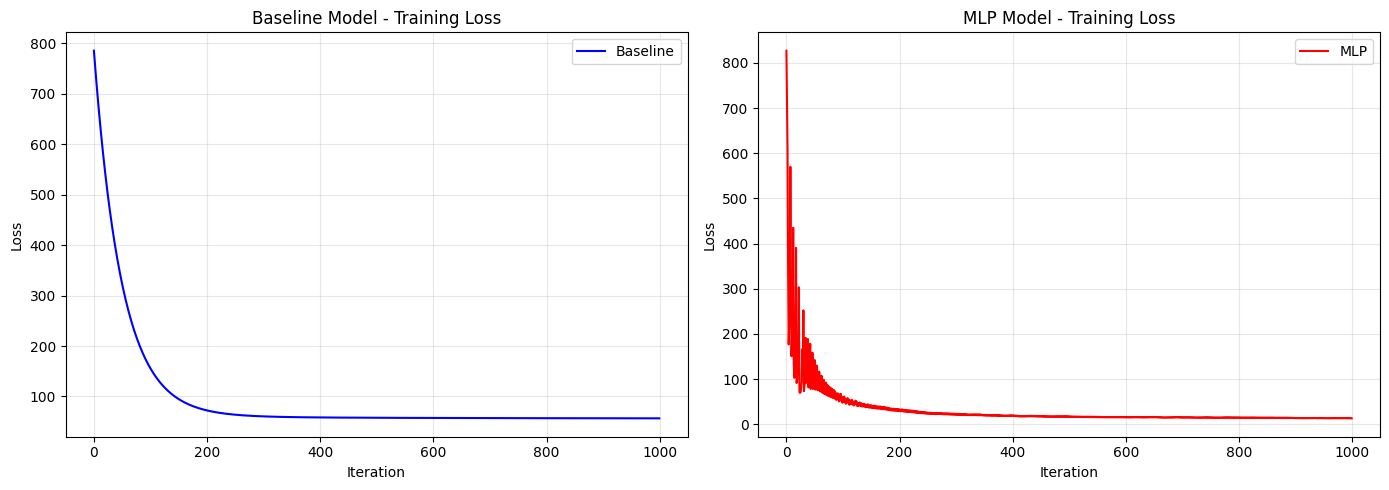

In [16]:
# 1. Training loss curves
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
# Plot baseline loss
plt.plot(baseline_model.loss_history, label='Baseline', color='blue')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('Baseline Model - Training Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
# Plot MLP loss
plt.plot(mlp_model.loss_history, label='MLP', color='red')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.title('MLP Model - Training Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

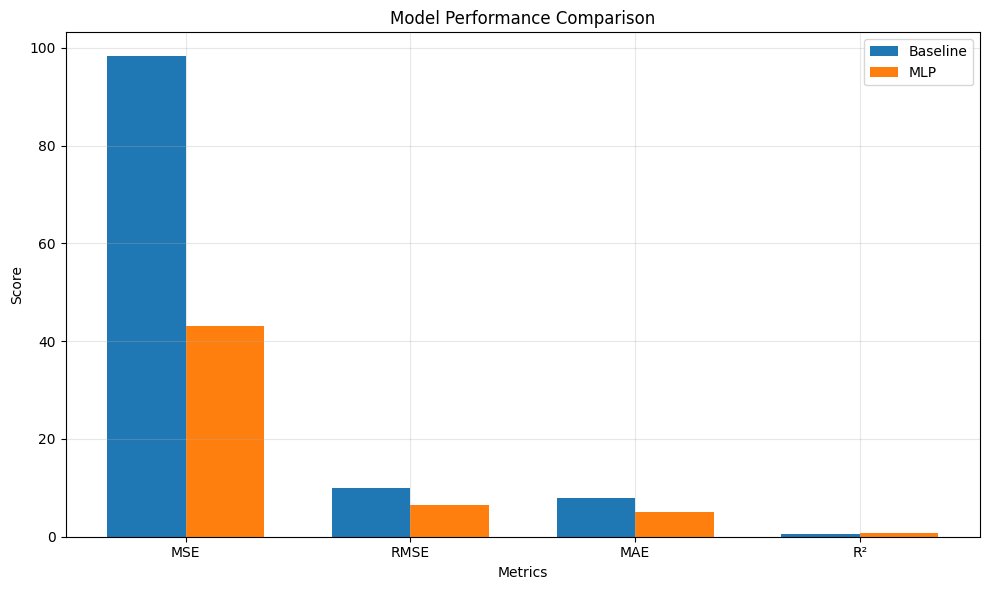

In [17]:
# 2. Performance comparison bar chart
plt.figure(figsize=(10, 6))

metrics = ['MSE', 'RMSE', 'MAE', 'R²']
baseline_scores = [baseline_metrics[m] for m in metrics]
mlp_scores = [mlp_metrics[m] for m in metrics]

x = np.arange(len(metrics))
width = 0.35

plt.bar(x - width/2, baseline_scores, width, label='Baseline')
plt.bar(x + width/2, mlp_scores, width, label='MLP')
plt.xlabel('Metrics')
plt.ylabel('Score')
plt.title('Model Performance Comparison')
plt.xticks(x, metrics)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Analysis

1. Which model performed better and by how much?
From the metric comparisons and visualizations made on the Baseline and MLP models, we find that MLP outperforms
the Baseline linear Model in every single metric. Out of the metrics calculated, we defined the most important
and primary metric to be RMSE because penalization of large errors is extremely important in concrete strength analysis.
In RMSE alone the MLP's predictions are off by 6.56 MPa on average versus the SLP's 9.91 MPa. In structural engineering terms,
that ~3.5 MPa difference is significant and could translate to real safety margins.

2. Why Did MLP Outperform Baseline Linear Model?
MLP outperformed the Baseline Model mainly because of its capability to learn non-linear patterns in data.
Concrete compressive strength is governed by complex chemical interactions — cement hydration, water-cement ratio effects,
superplasticizer interactions with fine aggregates, and the highly non-linear role of age.
The Baseline linear model with f(x) = x can only learn linear relationships via a hyperplane through the data
irrespective of how well gradient descent optimizes the weights.
MLP, however, with architecture [8, 16, 8, 1] (2 hidden layers) with ReLU activation introduces approximation of non-linear
boundaries to learn the relationships between data. The hidden layer of 16 neurons learns feature interactions
(e.g. cement × age, water × superplasticizer), while the compression to 8 neurons distills these into higher-order
representations.
The R² jump from 0.618 → 0.833 is the clearest evidence: the SLP explains only 61.8% of variance in concrete strength,
while the MLP explains 83.3% — a direct consequence of its ability to model the non-linear chemistry.

3. Computational Cost Difference
The MLP is more expensive per iteration due to:
- Two forward passes through hidden layers vs one in SLP
- Backpropagation through 3 layers with ReLU derivative computations vs direct gradient in SLP
- 289 parameters being updated vs 9 in SLP
However, looking at the loss curves, the MLP's loss drops far more steeply in early iterations — it converges to a much
lower loss in the same 1000 iterations. So while the MLP costs more per iteration, it delivers dramatically more value
per iteration. The trade-off heavily favors MLP here.

4. Surprising Findings and Challenges
The most visually surprise finding is the MLP loss curve — unlike the smooth exponential decay of the Linear Model,
the MLP shows violent oscillations in early iterations (loss spiking between ~50 and ~800 in the first 100 iterations)
before stabilizing.
Another notable finding is that the Linear Model's loss curve plateaus around 60–70 and refuses to go lower regardless
of further iterations — underfitting due to insufficient model capacity. The MLP converges to a loss near 20,
confirming it has the capacity to fit the underlying data distribution.

5. Insights Gained
Linear models are a special case of neural networks, and adding non-linear hidden layers strictly expands what is learnable.
The Linear Model (Single Layer Perceptron - SLP) is essentially the MLP with no hidden layers and linear activation —
and its performance ceiling is determined entirely by how linear the problem is.
For concrete strength prediction specifically, the data reflects real-world chemistry that follows non-linear physical laws.
No amount of hyperparameter tuning, more iterations, or better learning rates would allow the SLP to bridge the
0.215 R² gap — it is a fundamental architectural limitation, not a training limitation.
This is precisely why MLP is the right tool for this problem.